In [1]:
import numpy as np
def conv1d(x, w, p=0, s=1):
    """
    convolution operation for 1d array
    (mathmatical convolution definition, not the cross correlation used in CNN)
    """
    w_rot = np.array(w[::-1])
    x_padd = np.array(x)

    if p > 0:
        padd = np.zeros(shape=p)
        x_padd = np.concatenate([padd, x, padd])
    res=[]
    for i in range(0, (len(x_padd) - len(w_rot) + 1), s):
        res.append(np.sum(x_padd[i:i+w_rot.shape[0]] * w_rot))
    return np.array(res)

In [2]:
x = [1, 3, 2, 4, 5, 6, 1, 3]
w = [1, 0, 3, 1, 2]
print('Conv1d Implementation:',
    conv1d(x, w, p=2, s=1))
print('NumPy Results:',
    np.convolve(x, w, mode='same'))

Conv1d Implementation: [ 5. 14. 16. 26. 24. 34. 19. 22.]
NumPy Results: [ 5 14 16 26 24 34 19 22]


In [3]:
# naive/manual implementation of 2D convolution

def conv2d(X, W, p=(0,0), s=(1,1)):
    """
    convolution operation for 2d array
    (mathmatical convolution definition, not the cross correlation used in CNN)
    """
    W_rot = np.array(W)[::-1, ::-1]
    X = np.array(X)
    
    n = X.shape[0] + 2*p[0]
    m = X.shape[1] + 2*p[1]

    X_padd = np.zeros(shape=(n, m))
    X_padd[p[0]:p[0]+X.shape[0], p[1]:p[1]+X.shape[1]] = X

    res = []

    for i in range(0, int(n - W_rot.shape[0]) + 1, s[0]):
        res.append([])
        for j in range(0, int(m - W_rot.shape[1]) + 1, s[1]):
            X_slice = X_padd[i:i+W_rot.shape[0], j:j+W_rot.shape[1]]
            res[-1].append(np.sum(X_slice * W_rot))
    return np.array(res)

In [4]:
X = [[1, 3, 2, 4], [5, 6, 1, 3], [1, 2, 0, 2], [3, 4, 3, 2]]
W = [[1, 0, 3], [1, 2, 1], [0, 1, 1]]
print('Conv2d Implementation:\n',
    conv2d(X, W, p=(1, 1), s=(1, 1)))

Conv2d Implementation:
 [[11. 25. 32. 13.]
 [19. 25. 24. 13.]
 [13. 28. 25. 17.]
 [11. 17. 14.  9.]]


In [5]:
# L2 regularization for NN
import torch
import torch.nn as nn

loss_func = nn.BCELoss()
loss = loss_func(torch.tensor([0.9]), torch.tensor([1.0]))

l2_lambda = 0.001

model = nn.Conv2d(in_channels=3, out_channels=5, kernel_size=5)

l2_penalty = l2_lambda * sum(p.pow(2).sum() for p in model.parameters())
loss_with_penalty = loss + l2_penalty
print(loss_with_penalty)

tensor(0.1072, grad_fn=<AddBackward0>)


In [ ]:
# Implement Deep CNN with PyTorch on MNIST dataset

import torchvision
from torchvision import transforms

image_path = "./"

transform = transforms.Compose([
    transforms.ToTensor()
])

mnist_data = torchvision.datasets.MNIST(
    root=image_path, train=True, transform=transform, download=True
)

100%|██████████| 9.91M/9.91M [00:03<00:00, 3.05MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 653kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.82MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.45MB/s]


In [8]:
from torch.utils.data import Subset
mnist_valid_dataset = Subset(mnist_data, torch.arange(1000))
mnist_train_dataset = Subset(mnist_data, torch.arange(1000, len(mnist_data)))
mnist_test_dataset = torchvision.datasets.MNIST(
    root=image_path, train=False, transform=transform, download=False
)

In [9]:
from torch.utils.data import DataLoader
batch_size = 64
torch.manual_seed(1)
train_dl = DataLoader(mnist_train_dataset,
    batch_size,
    shuffle=True)
valid_dl = DataLoader(mnist_valid_dataset,
    batch_size,
    shuffle=False)

In [10]:
# L2 regularization for NN
import torch
import torch.nn as nn

model = nn.Sequential()

model.add_module(
    "conv1",
    nn.Conv2d(
        in_channels=1, out_channels=32,kernel_size=5, padding=2
    )
)

model.add_module(
    "relu1",
    nn.ReLU()
)
model.add_module(
    "pool1",
    nn.MaxPool2d(kernel_size=2)
)

model.add_module(
    'conv2',
    nn.Conv2d(
        in_channels=32, out_channels=64,
        kernel_size=5, padding=2
    )
)
model.add_module('relu2', nn.ReLU())
model.add_module('pool2', nn.MaxPool2d(kernel_size=2))

In [ ]:
# check output shape
x = torch.ones((4,1,28,28))
model(x).shape

torch.Size([4, 64, 7, 7])

In [ ]:
# add flatten layer
model.add_module("flatten", nn.Flatten())

In [15]:
# check output shape
model(x).shape

torch.Size([4, 3136])

In [16]:
# fully connected layer
model.add_module('fc1', nn.Linear(3136, 1024))
model.add_module('relu3', nn.ReLU())
model.add_module('dropout', nn.Dropout(p=0.5))
model.add_module('fc2', nn.Linear(1024, 10))

In [17]:
loss_fn = nn.CrossEntropyLoss()    #crossEntropy apply softmax internally
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [19]:
def train(model, num_epochs, train_dl, valid_dl):
    loss_hist_train = [0] * num_epochs
    accuracy_hist_train = [0] * num_epochs
    loss_hist_valid = [0] * num_epochs
    accuracy_hist_valid = [0] * num_epochs
    for epoch in range(num_epochs):
        model.train()
        for x_batch, y_batch in train_dl:
            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            loss_hist_train[epoch] += loss.item()*y_batch.size(0)
            is_correct = (
                torch.argmax(pred, dim=1) == y_batch
            ).float()
            accuracy_hist_train[epoch] += is_correct.sum()
        loss_hist_train[epoch] /= len(train_dl.dataset)
        accuracy_hist_train[epoch] /= len(train_dl.dataset)

        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in valid_dl:
                pred = model(x_batch)
                loss = loss_fn(pred, y_batch)
                loss_hist_valid[epoch] += \
                    loss.item()*y_batch.size(0)
                is_correct = (
                    torch.argmax(pred, dim=1) == y_batch
                ).float()
                accuracy_hist_valid[epoch] += is_correct.sum()
        loss_hist_valid[epoch] /= len(valid_dl.dataset)
        accuracy_hist_valid[epoch] /= len(valid_dl.dataset)

        print(f'Epoch {epoch+1} accuracy: '
              f'{accuracy_hist_train[epoch]:.4f} val_accuracy: '
              f'{accuracy_hist_valid[epoch]:.4f}')
    return loss_hist_train, loss_hist_valid, \
           accuracy_hist_train, accuracy_hist_valid

In [21]:
torch.manual_seed(1)
num_epochs = 20
hist = train(model, num_epochs, train_dl, valid_dl)

Epoch 1 accuracy: 0.9935 val_accuracy: 0.9890
Epoch 2 accuracy: 0.9959 val_accuracy: 0.9920
Epoch 3 accuracy: 0.9940 val_accuracy: 0.9930
Epoch 4 accuracy: 0.9943 val_accuracy: 0.9900
Epoch 5 accuracy: 0.9956 val_accuracy: 0.9920
Epoch 6 accuracy: 0.9965 val_accuracy: 0.9930
Epoch 7 accuracy: 0.9967 val_accuracy: 0.9930
Epoch 8 accuracy: 0.9972 val_accuracy: 0.9940
Epoch 9 accuracy: 0.9972 val_accuracy: 0.9920
Epoch 10 accuracy: 0.9976 val_accuracy: 0.9920
Epoch 11 accuracy: 0.9973 val_accuracy: 0.9920
Epoch 12 accuracy: 0.9977 val_accuracy: 0.9850
Epoch 13 accuracy: 0.9984 val_accuracy: 0.9940
Epoch 14 accuracy: 0.9982 val_accuracy: 0.9940
Epoch 15 accuracy: 0.9981 val_accuracy: 0.9910
Epoch 16 accuracy: 0.9977 val_accuracy: 0.9910
Epoch 17 accuracy: 0.9984 val_accuracy: 0.9920
Epoch 18 accuracy: 0.9983 val_accuracy: 0.9930
Epoch 19 accuracy: 0.9981 val_accuracy: 0.9860
Epoch 20 accuracy: 0.9987 val_accuracy: 0.9920


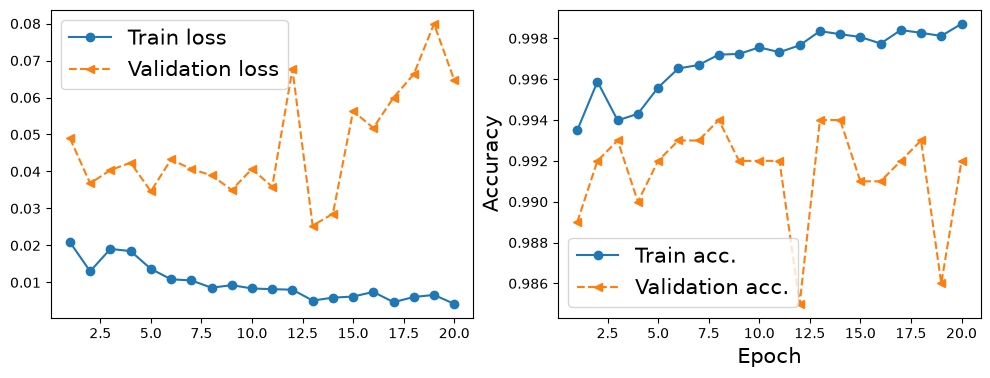

In [22]:
import matplotlib.pyplot as plt

x_arr = np.arange(len(hist[0])) + 1
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(x_arr, hist[0], '-o', label='Train loss')
ax.plot(x_arr, hist[1], '--<', label='Validation loss')
ax.legend(fontsize=15)
ax = fig.add_subplot(1, 2, 2)
ax.plot(x_arr, hist[2], '-o', label='Train acc.')
ax.plot(x_arr, hist[3], '--<', label='Validation acc.')
ax.legend(fontsize=15)
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Accuracy', size=15)
plt.show()

In [23]:
pred = model(mnist_test_dataset.data.unsqueeze(1) / 255.)
is_correct = (
    torch.argmax(pred, dim=1) == mnist_test_dataset.targets
).float()
print(f'Test accuracy: {is_correct.mean():.4f}')

Test accuracy: 0.9934


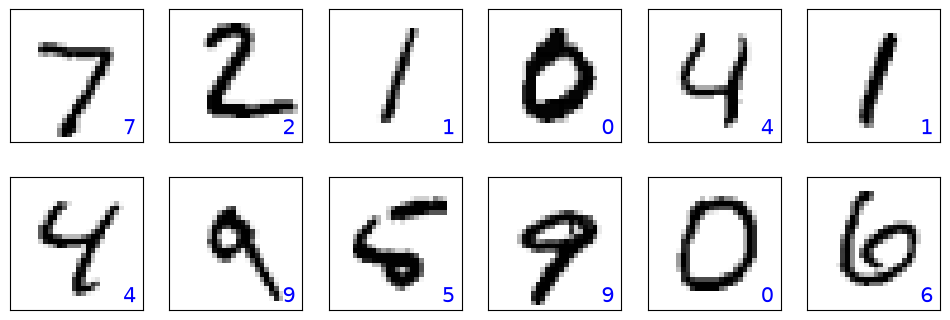

In [24]:
fig = plt.figure(figsize=(12, 4))
for i in range(12):
    ax = fig.add_subplot(2, 6, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    img = mnist_test_dataset[i][0][0, :, :]
    pred = model(img.unsqueeze(0).unsqueeze(1))
    y_pred = torch.argmax(pred)
    ax.imshow(img, cmap='gray_r')
    ax.text(0.9, 0.1, y_pred.item(),
        size=15, color='blue',
        horizontalalignment='center',
        verticalalignment='center',
        transform=ax.transAxes)
plt.show()